## **Messwerte (Leerlauf)**

In [1]:
import numpy as np


f_1 = 130 #Erste Frequenz in Hz
f_1_Fehler = 1
omega_1 = f_1 * 2*np.pi
omega_1_Fehler = f_1_Fehler * 2*np.pi

N_1 = 50 #Primärwindungszahl
N_2 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Sekundärwindungszahl

U1_f1 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Primärspannung bei Frequenz 1 in Volt
U1_f1_Fehler = 1

I1_f1 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Primärstrom bei Frequenz 1 in Ampere
I1_f1_Fehler = 1

U2_f1 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Sekundärspannung bei Frequenz 1 in Volt
U2_f1_Fehler = 1



"""-----------------------------------------------------------------------------------------------------------------------------------"""



f_2 = 320 #Zweite Frequenz in Hz
f_2_Fehler = 1
omega_2 = f_2 * 2*np.pi
omega_2_Fehler = f_2_Fehler * 2*np.pi

U1_f2 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Primärspannung bei Frequenz 2 in Volt
U1_f2_Fehler = 1

I1_f2 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Primärstrom bei Frequenz 2 in Ampere
I1_f2_Fehler = 1

U2_f2 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]) #Sekundärspannung bei Frequenz 2 in Volt
U2_f2_Fehler = 1


## **Berechnung der Induktivitäten für f_1**

In [2]:
import sympy as sp
from Skripte.Fehlerfortpflanzung import Gaußfehler
from IPython.display import display

#Berechnungen für Frequenz 1

#Berechung von L1
L1_f1 = U1_f1 / (omega_1 * I1_f1)
L1_f1_Fehler = np.zeros(len(L1_f1), dtype = float)

U1p, omega1p, I1p = sp.symbols("U_1, omega_1, I_1")
expr1 = U1p / (omega1p * I1p)
display(expr1)
Variablen_1 = np.array([U1p, omega1p, I1p])

Fehler_1 = np.array([U1_f1_Fehler, omega_1_Fehler, I1_f1_Fehler])

for i in range(len(L1_f1_Fehler)):
    L1_f1_Fehler[i] = Gaußfehler(expr1, Variablen_1, np.array([U1_f1[i], omega_1, I1_f1[i]]), Fehler_1)

#Berechnung von L12
L12_f1 = U2_f1 / (omega_1 * I1_f1)
L12_f1_Fehler = np.zeros(len(L12_f1), dtype = float)

U2p, omega1p, I1p = sp.symbols("U_2, omega_1, I_1")
expr2 = U2p / (omega1p * I1p)
display(expr2)
Variablen_2 = np.array([U2p, omega1p, I1p])

Fehler_2 = np.array([U2_f1_Fehler, omega_1_Fehler, I1_f1_Fehler])

for i in range(len(L12_f1_Fehler)):
    L12_f1_Fehler[i] = Gaußfehler(expr2, Variablen_2, np.array([U2_f1[i], omega_1, I1_f1[i]]), Fehler_2)

print(f"Induktivitäten für f_1 = {f_1}Hz:")
for i in range(len(L1_f1)):
    print(f"für N_2 = {N_2[i]} gilt: L_1 = ({L1_f1[i]} +/- {L1_f1_Fehler[i]})H und Kopplung L_12 = ({L12_f1[i]} +/- {L12_f1_Fehler[i]})H")

%store L12_f1
%store L12_f1_Fehler
%store L1_f1
%store L1_f1_Fehler

U_1/(I_1*omega_1)

U_2/(I_1*omega_1)

Induktivitäten für f_1 = 130Hz:
für N_2 = 1 gilt: L_1 = (0.0012242687930145797 +/- 0.0017314031429755772)H und Kopplung L_12 = (0.0012242687930145797 +/- 0.0017314031429755772)H
für N_2 = 2 gilt: L_1 = (0.0012242687930145797 +/- 0.0008657399882075701)H und Kopplung L_12 = (0.0012242687930145797 +/- 0.0008657399882075701)H
für N_2 = 3 gilt: L_1 = (0.0012242687930145797 +/- 0.000577202674857257)H und Kopplung L_12 = (0.0012242687930145797 +/- 0.000577202674857257)H
für N_2 = 4 gilt: L_1 = (0.0012242687930145797 +/- 0.00043294681902125985)H und Kopplung L_12 = (0.0012242687930145797 +/- 0.00043294681902125985)H
für N_2 = 5 gilt: L_1 = (0.0012242687930145797 +/- 0.00034640354301147905)H und Kopplung L_12 = (0.0012242687930145797 +/- 0.00034640354301147905)H
für N_2 = 6 gilt: L_1 = (0.0012242687930145797 +/- 0.00028871655351020274)H und Kopplung L_12 = (0.0012242687930145797 +/- 0.00028871655351020274)H
für N_2 = 7 gilt: L_1 = (0.0012242687930145797 +/- 0.00024751886702112206)H und Kopplung

## **Berechnung der Induktivitäten für f_2**

In [3]:
#Berechnungen für Frequenz 2

#Berechung von L1
L1_f2 = U1_f2 / (omega_2 * I1_f2)
L1_f2_Fehler = np.zeros(len(L1_f2), dtype = float)

U1p, omega2p, I1p = sp.symbols("U_1, omega_2, I_1")
expr1 = U1p / (omega2p * I1p)
display(expr1)
Variablen_1 = np.array([U1p, omega2p, I1p])

Fehler_1 = np.array([U1_f2_Fehler, omega_2_Fehler, I1_f2_Fehler])

for i in range(len(L1_f2_Fehler)):
    L1_f2_Fehler[i] = Gaußfehler(expr1, Variablen_1, np.array([U1_f2[i], omega_2, I1_f2[i]]), Fehler_1)

#Berechnung von L12
L12_f2 = U2_f2 / (omega_2 * I1_f2)
L12_f2_Fehler = np.zeros(len(L12_f2), dtype = float)

U2p, omega2p, I1p = sp.symbols("U_2, omega_2, I_1")
expr2 = U2p / (omega2p * I1p)
display(expr2)
Variablen_2 = np.array([U2p, omega2p, I1p])

Fehler_2 = np.array([U2_f2_Fehler, omega_2_Fehler, I1_f2_Fehler])

for i in range(len(L12_f2_Fehler)):
    L12_f2_Fehler[i] = Gaußfehler(expr2, Variablen_2, np.array([U2_f2[i], omega_2, I1_f2[i]]), Fehler_2)

print(f"Induktivitäten für f_2 = {f_2}Hz:")
for i in range(len(L1_f2)):
    print(f"für N_2 = {N_2[i]} gilt: L_1 = ({L1_f2[i]} +/- {L1_f2_Fehler[i]})H und Kopplung L_12 = ({L12_f2[i]} +/- {L12_f2_Fehler[i]})H")

%store L12_f2
%store L12_f2_Fehler
%store L1_f2
%store L1_f2_Fehler

U_1/(I_1*omega_2)

U_2/(I_1*omega_2)

Induktivitäten für f_2 = 320Hz:
für N_2 = 1 gilt: L_1 = (0.0004973591971621729 +/- 0.0007033738392127377)H und Kopplung L_12 = (0.0004973591971621729 +/- 0.0007033738392127377)H
für N_2 = 2 gilt: L_1 = (0.0004973591971621729 +/- 0.00035168949541628945)H und Kopplung L_12 = (0.0004973591971621729 +/- 0.00035168949541628945)H
für N_2 = 3 gilt: L_1 = (0.0004973591971621729 +/- 0.00023446252559393408)H und Kopplung L_12 = (0.0004973591971621729 +/- 0.00023446252559393408)H
für N_2 = 4 gilt: L_1 = (0.0004973591971621729 +/- 0.00017584989923366133)H und Kopplung L_12 = (0.0004973591971621729 +/- 0.00017584989923366133)H
für N_2 = 5 gilt: L_1 = (0.0004973591971621729 +/- 0.0001406830102230109)H und Kopplung L_12 = (0.0004973591971621729 +/- 0.0001406830102230109)H
für N_2 = 6 gilt: L_1 = (0.0004973591971621729 +/- 0.00011723898984944945)H und Kopplung L_12 = (0.0004973591971621729 +/- 0.00011723898984944945)H
für N_2 = 7 gilt: L_1 = (0.0004973591971621729 +/- 0.00010049375151471098)H und Kopp

## **Kopplungsgrad aus linearer Regression**

U_2/U_1

Kopplungsgrad für f_1 = 130: kappa = 4.900636594400562e-09 +/- 0.0598104003848994
Kopplungsgrad für f_2 = 320: kappa = 4.900636594400562e-09 +/- 0.0598104003848994


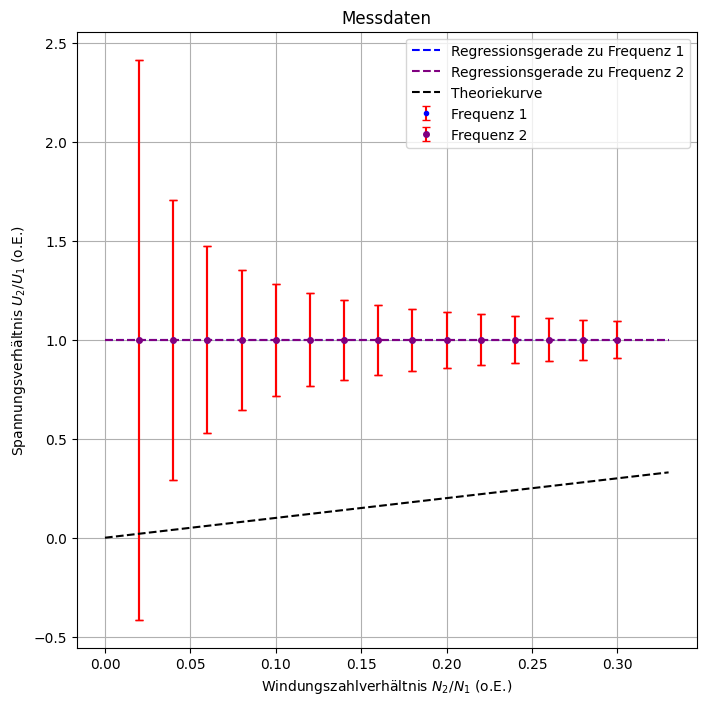

In [4]:
import scipy.optimize
import matplotlib.pyplot as plt

N_Ratio = N_2 / N_1

U1p, U2p = sp.symbols("U_1, U_2")
expr3 = U2p / U1p
display(expr3)
Variablen = np.array([U1p, U2p])

#Frequenz 1
U_Ratio_f1 = U2_f1 / U1_f1
U_Ratio_f1_Fehler = np.zeros(len(U_Ratio_f1), dtype = float)

for i in range(len(U_Ratio_f1_Fehler)):
    U_Ratio_f1_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([U1_f1[i], U2_f1[i]]), np.array([U1_f1_Fehler, U2_f1_Fehler]))

#Frequenz 2
U_Ratio_f2 = U2_f2 / U1_f2
U_Ratio_f2_Fehler = np.zeros(len(U_Ratio_f2), dtype = float)

for i in range(len(U_Ratio_f2_Fehler)):
    U_Ratio_f2_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([U1_f2[i], U2_f2[i]]), np.array([U1_f2_Fehler, U2_f2_Fehler]))

#Lineare Regression

def f(x,k,c):
    return k*x + c #Fit Funktion

coefficients1, pcov1 = scipy.optimize.curve_fit(f, N_Ratio, U_Ratio_f1, sigma= U_Ratio_f1_Fehler, absolute_sigma= True)
kappa_1 = coefficients1[0]
kappa_1_Fehler = np.sqrt(pcov1[0,0])
c_1 = coefficients1[1]

print(f"Kopplungsgrad für f_1 = {f_1}: kappa = {kappa_1} +/- {kappa_1_Fehler}")

coefficients2, pcov2 = scipy.optimize.curve_fit(f, N_Ratio, U_Ratio_f2, sigma= U_Ratio_f2_Fehler, absolute_sigma= True)
kappa_2 = coefficients2[0]
kappa_2_Fehler = np.sqrt(pcov2[0,0])
c_2 = coefficients2[1]

print(f"Kopplungsgrad für f_2 = {f_2}: kappa = {kappa_2} +/- {kappa_2_Fehler}")

#Plot
fig, ax1 = plt.subplots(1, 1, figsize=(8, 8))

ax1.errorbar(N_Ratio, U_Ratio_f1, yerr=U_Ratio_f1_Fehler, fmt="o", label="Frequenz 1", color="blue", markersize=3, capsize=3, ecolor="r")
ax1.errorbar(N_Ratio, U_Ratio_f2, yerr=U_Ratio_f2_Fehler, fmt="o", label="Frequenz 2", color="purple", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(0, np.max(N_Ratio)*1.1, 500)
ax1.plot(xwerte, kappa_1*xwerte + c_1, color = "blue", linestyle = "--", label = "Regressionsgerade zu Frequenz 1")
ax1.plot(xwerte, kappa_2*xwerte + c_2, color = "purple", linestyle = "--", label = "Regressionsgerade zu Frequenz 2")

ax1.plot(xwerte, xwerte, color = "black", linestyle = "--", label = "Theoriekurve")

ax1.set_xlabel(r"Windungszahlverhältnis $N_2/N_1$ (o.E.)")
ax1.set_ylabel(r"Spannungsverhältnis $U_2/U_1$ (o.E.)")
ax1.grid(True)
ax1.set_title("Messdaten")
ax1.legend()
